In [19]:
# CRNN - Music Genre Classification

import json
import numpy as np
from sklearn.model_selection import train_test_split
import tensorflow.keras as keras
import matplotlib.pyplot as plt


In [20]:
DATA_PATH = "data.json"

print("Data path:", DATA_PATH)

Data path: data.json


In [21]:
def load_data(data_path):
    """Load MFCC dataset from JSON file."""

    with open(data_path, "r") as fp:
        data = json.load(fp)

    X = np.array(data["mfcc"])
    y = np.array(data["labels"])

    return X, y

In [22]:
X, y = load_data(DATA_PATH)

print("X shape:", X.shape)
print("y shape:", y.shape)
print("Number of samples:", len(X))
print("Number of classes:", len(np.unique(y)))

X shape: (9996, 130, 13)
y shape: (9996,)
Number of samples: 9996
Number of classes: 10


In [2]:
def plot_history(history):
    """Plot training and validation accuracy/loss."""

    fig, axs = plt.subplots(2, figsize=(10, 8))

    # Accuracy
    axs[0].plot(
        history.history["accuracy"],
        label="Train Accuracy"
    )

    axs[0].plot(
        history.history["val_accuracy"],
        label="Validation Accuracy"
    )

    axs[0].set_ylabel("Accuracy")
    axs[0].set_title("Accuracy Evaluation")
    axs[0].legend(loc="lower right")

    # Loss
    axs[1].plot(
        history.history["loss"],
        label="Train Loss"
    )

    axs[1].plot(
        history.history["val_loss"],
        label="Validation Loss"
    )

    axs[1].set_ylabel("Loss")
    axs[1].set_xlabel("Epoch")
    axs[1].set_title("Loss Evaluation")
    axs[1].legend(loc="upper right")

    plt.tight_layout()
    plt.show()

In [24]:
def prepare_datasets(test_size=0.25, validation_size=0.20):

    X, y = load_data(DATA_PATH)

    # Train-Test Split
    X_train, X_test, y_train, y_test = train_test_split(
        X,
        y,
        test_size=test_size,
        random_state=42,
        stratify=y
    )

    # Train-Validation Split
    X_train, X_validation, y_train, y_validation = train_test_split(
        X_train,
        y_train,
        test_size=validation_size,
        random_state=42,
        stratify=y_train
    )

    # Add channel dimension
    X_train = X_train[..., np.newaxis]
    X_validation = X_validation[..., np.newaxis]
    X_test = X_test[..., np.newaxis]

    return (
        X_train,
        X_validation,
        X_test,
        y_train,
        y_validation,
        y_test
    )

In [25]:
X_train, X_validation, X_test, y_train, y_validation, y_test = \
    prepare_datasets(
        test_size=0.25,
        validation_size=0.20
    )

print("Training data:", X_train.shape)
print("Validation data:", X_validation.shape)
print("Test data:", X_test.shape)

print("\nTraining labels:", y_train.shape)
print("Validation labels:", y_validation.shape)
print("Test labels:", y_test.shape)

Training data: (5997, 130, 13, 1)
Validation data: (1500, 130, 13, 1)
Test data: (2499, 130, 13, 1)

Training labels: (5997,)
Validation labels: (1500,)
Test labels: (2499,)


In [26]:
def build_model(input_shape):

    model = keras.Sequential()

    # 1st CNN layer
    model.add(
        keras.layers.Conv2D(
            32,
            (3, 3),
            activation="relu",
            input_shape=input_shape
        )
    )

    model.add(
        keras.layers.MaxPooling2D(
            (3, 3),
            strides=(2, 2),
            padding="same"
        )
    )

    model.add(keras.layers.BatchNormalization())

    # 2nd CNN layer
    model.add(
        keras.layers.Conv2D(
            32,
            (3, 3),
            activation="relu"
        )
    )

    model.add(
        keras.layers.MaxPooling2D(
            (3, 3),
            strides=(2, 2),
            padding="same"
        )
    )

    model.add(keras.layers.BatchNormalization())

    # 3rd CNN layer
    model.add(
        keras.layers.Conv2D(
            32,
            (2, 2),
            activation="relu",
            name="conv3"
        )
    )

    model.add(
        keras.layers.MaxPooling2D(
            (2, 2),
            strides=(2, 2),
            padding="same"
        )
    )

    model.add(keras.layers.BatchNormalization())

    # Convert CNN output into sequence
    model.add(
        keras.layers.Reshape((-1, 32))
    )

    # LSTM layers
    model.add(
        keras.layers.LSTM(
            64,
            return_sequences=True
        )
    )

    model.add(
        keras.layers.LSTM(64)
    )

    # Dense layer
    model.add(
        keras.layers.Dense(
            64,
            activation="relu"
        )
    )

    model.add(
        keras.layers.Dropout(0.3)
    )

    # Output layer
    model.add(
        keras.layers.Dense(
            10,
            activation="softmax"
        )
    )

    return model

In [27]:
input_shape = (
    X_train.shape[1],
    X_train.shape[2],
    1
)

model = build_model(input_shape)

print("Input shape:", input_shape)

model.summary()

Input shape: (130, 13, 1)


C:\Users\JITENDRA KUMAR\AppData\Roaming\Python\Python313\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━┓
┃ Layer (type)                  ┃ Output Shape          ┃      Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)             │ (None, 128, 11, 32)   │          320 │
├───────────────────────────────┼───────────────────────┼──────────────┤
│ max_pooling2d_3               │ (None, 64, 6, 32)     │            0 │
│ (MaxPooling2D)                │                       │              │
├───────────────────────────────┼───────────────────────┼──────────────┤
│ batch_normalization_3         │ (None, 64, 6, 32)     │          128 │
│ (BatchNormalization)          │                       │              │
├───────────────────────────────┼───────────────────────┼──────────────┤
│ conv2d_4 (Conv2D)             │ (None, 62, 4, 32)     │        9,248 │
├───────────────────────────────┼───────────────────────┼──────────────┤
│ max_pooling2d_4               │ (None, 31, 2, 32)     │            0 │
│ (MaxPooling2D)                │                       │              │
├───────────────────────────────┼───────────────────────┼──────────────┤
│ batch_normalization_4         │ (None, 31, 2, 32)     │          128 │
│ (BatchNormalization)          │                       │              │
├───────────────────────────────┼───────────────────────┼──────────────┤
│ conv3 (Conv2D)                │ (None, 30, 1, 32)     │        4,128 │
├───────────────────────────────┼───────────────────────┼──────────────┤
│ max_pooling2d_5               │ (None, 15, 1, 32)     │            0 │
│ (MaxPooling2D)                │                       │              │
├───────────────────────────────┼───────────────────────┼──────────────┤
│ batch_normalization_5         │ (None, 15, 1, 32)     │          128 │
│ (BatchNormalization)          │                       │              │
├───────────────────────────────┼───────────────────────┼──────────────┤
│ reshape (Reshape)             │ (None, 15, 32)        │            0 │
├───────────────────────────────┼───────────────────────┼──────────────┤
│ lstm (LSTM)                   │ (None, 15, 64)        │       24,832 │
├───────────────────────────────┼───────────────────────┼──────────────┤
│ lstm_1 (LSTM)                 │ (None, 64)            │       33,024 │
├───────────────────────────────┼───────────────────────┼──────────────┤
│ dense_2 (Dense)               │ (None, 64)            │        4,160 │
├───────────────────────────────┼───────────────────────┼──────────────┤
│ dropout_1 (Dropout)           │ (None, 64)            │            0 │
├───────────────────────────────┼───────────────────────┼──────────────┤
│ dense_3 (Dense)               │ (None, 10)            │          650 │
└───────────────────────────────┴───────────────────────┴──────────────┘

 Total params: 76,746 (299.79 KB)

 Trainable params: 76,554 (299.04 KB)

 Non-trainable params: 192 (768.00 B)

In [28]:
optimizer = keras.optimizers.Adam(
    learning_rate=0.0001
)

model.compile(
    optimizer=optimizer,
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("CRNN model compiled successfully!")

CRNN model compiled successfully!


In [29]:
history = model.fit(
    X_train,
    y_train,
    validation_data=(X_validation, y_validation),
    batch_size=32,
    epochs=30
)

Epoch 1/30
188/188 ━━━━━━━━━━━━━━━━━━━━ 7s 20ms/step - accuracy: 0.2886 - loss: 2.0627 - val_accuracy: 0.4047 - val_loss: 1.8685
Epoch 2/30
188/188 ━━━━━━━━━━━━━━━━━━━━ 3s 17ms/step - accuracy: 0.4280 - loss: 1.6673 - val_accuracy: 0.5167 - val_loss: 1.4773
Epoch 3/30
188/188 ━━━━━━━━━━━━━━━━━━━━ 3s 17ms/step - accuracy: 0.4977 - loss: 1.4313 - val_accuracy: 0.5553 - val_loss: 1.3086
Epoch 4/30
188/188 ━━━━━━━━━━━━━━━━━━━━ 3s 18ms/step - accuracy: 0.5428 - loss: 1.3056 - val_accuracy: 0.5833 - val_loss: 1.2010
Epoch 5/30
188/188 ━━━━━━━━━━━━━━━━━━━━ 3s 16ms/step - accuracy: 0.5851 - loss: 1.2015 - val_accuracy: 0.5920 - val_loss: 1.1381
Epoch 6/30
188/188 ━━━━━━━━━━━━━━━━━━━━ 3s 18ms/step - accuracy: 0.6041 - loss: 1.1449 - val_accuracy: 0.6180 - val_loss: 1.0909
Epoch 7/30
188/188 ━━━━━━━━━━━━━━━━━━━━ 3s 18ms/step - accuracy: 0.6342 - loss: 1.0834 - val_accuracy: 0.6413 - val_loss: 1.0279
Epoch 8/30
188/188 ━━━━━━━━━━━━━━━━━━━━ 3s 16ms/step - accuracy: 0.6443 - loss: 1.0443 - val_accu

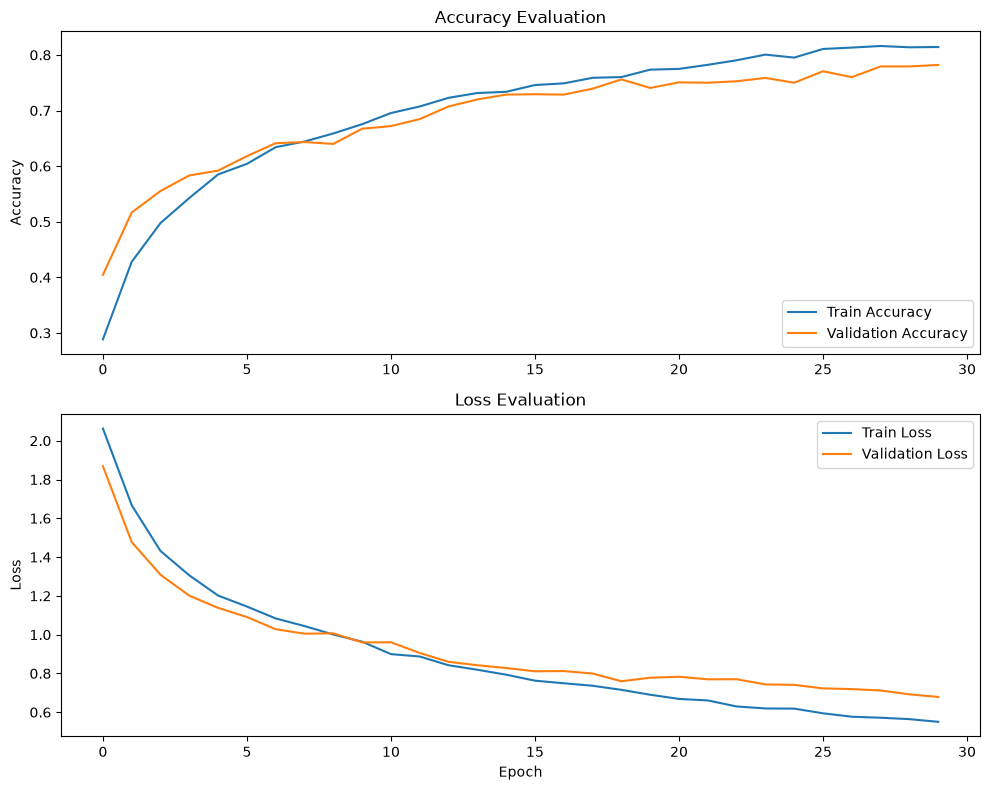

In [30]:
plot_history(history)

In [31]:
test_loss, test_acc = model.evaluate(
    X_test,
    y_test,
    verbose=2
)

print("\nTest Loss:", test_loss)
print("Test Accuracy:", test_acc)
print("Test Accuracy (%):", test_acc * 100)

79/79 - 1s - 7ms/step - accuracy: 0.7815 - loss: 0.6371

Test Loss: 0.6370881199836731
Test Accuracy: 0.7815126180648804
Test Accuracy (%): 78.15126180648804


In [32]:
with open(DATA_PATH, "r") as fp:
    data = json.load(fp)

genres = data["mapping"]

print("Genres:")

for i, genre in enumerate(genres):
    print(i, ":", genre)

Genres:
0 : blues
1 : classical
2 : country
3 : disco
4 : hiphop
5 : jazz
6 : metal
7 : pop
8 : reggae
9 : rock


In [33]:
def predict(model, X, y):

    # Add batch dimension
    X = X[np.newaxis, ...]

    # Prediction
    prediction = model.predict(
        X,
        verbose=0
    )

    # Get predicted class
    predicted_index = np.argmax(
        prediction,
        axis=1
    )[0]

    print("Actual Genre   :", genres[y])
    print("Predicted Genre :", genres[predicted_index])

In [34]:
X_to_predict = X_test[100]
y_to_predict = y_test[100]

predict(
    model,
    X_to_predict,
    y_to_predict
)

Actual Genre   : metal
Predicted Genre : metal


In [35]:
genre_accuracy = {}

for genre_id in range(10):

    genre_mask = (y_test == genre_id)

    X_genre = X_test[genre_mask]
    y_genre = y_test[genre_mask]

    test_loss_genre, test_acc_genre = model.evaluate(
        X_genre,
        y_genre,
        verbose=0
    )

    genre_accuracy[genre_id] = test_acc_genre

    print(
        f"{genres[genre_id]:10s} : "
        f"{test_acc_genre * 100:.2f}%"
    )

blues      : 82.80%
classical  : 90.00%
country    : 70.28%
disco      : 80.80%
hiphop     : 82.00%
jazz       : 89.60%
metal      : 90.40%
pop        : 77.20%
reggae     : 61.20%
rock       : 57.20%


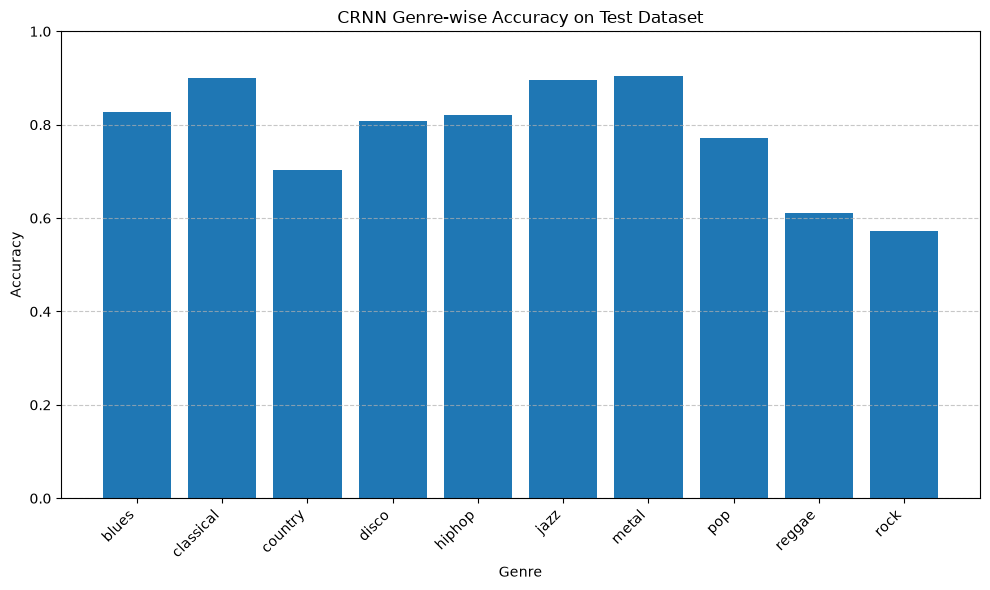

In [36]:
accuracy_values = [
    genre_accuracy[i]
    for i in range(10)
]

plt.figure(figsize=(10, 6))

plt.bar(
    genres,
    accuracy_values
)

plt.title("CRNN Genre-wise Accuracy on Test Dataset")
plt.xlabel("Genre")
plt.ylabel("Accuracy")

plt.xticks(
    rotation=45,
    ha="right"
)

plt.ylim(0, 1)

plt.grid(
    axis="y",
    linestyle="--",
    alpha=0.7
)

plt.tight_layout()
plt.show()